### Task 1

Counts images & labels, auto-detects folder layout

In [4]:
# ============================================================
# TASK 1 — Inspect the Dataset
# ============================================================

import os
import random
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
import pandas as pd
import numpy as np

# ── 1. Point this at your dataset ──────────────────────────
DATA_ROOT = Path("C:/Users/user/BootcampLabs/m6-04-assessment/m6-04-assessment/DATA_CLEAN-20260521T192120Z-3-001")   # adjust if your path differs

# Auto-detect layout: separate images/ & labels/ folders,
# OR everything in one flat folder
if (DATA_ROOT / "images").exists():
    images_dir = DATA_ROOT / "images"
    labels_dir = DATA_ROOT / "labels"
else:
    images_dir = DATA_ROOT
    labels_dir = DATA_ROOT

IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

image_paths = sorted([p for p in images_dir.rglob("*") if p.suffix.lower() in IMG_EXTS])
label_paths = sorted([p for p in labels_dir.rglob("*.txt")])

print(f"Images found : {len(image_paths)}")
print(f"Label files  : {len(label_paths)}")

Images found : 976
Label files  : 1051


Lists any broken image↔label pairs

In [5]:
# 2. Check that every image has a matching label
image_stems = {p.stem for p in image_paths}
label_stems = {p.stem for p in label_paths}

images_missing_labels = image_stems - label_stems
labels_missing_images = label_stems - image_stems

print(f"\nImages with NO matching label : {len(images_missing_labels)}")
print(f"Labels with NO matching image : {len(labels_missing_images)}")

if images_missing_labels:
    print("  Examples:", list(images_missing_labels)[:5])
if labels_missing_images:
    print("  Examples:", list(labels_missing_images)[:5])


Images with NO matching label : 244
Labels with NO matching image : 326
  Examples: ['2c30b6de759829dc', '035c1f8899cc6710', '55dedd165a7b2107', '0818e3857f6643f4', '32f8cf5cf30f863f']
  Examples: ['3d18d322975589a8', '3a6aa4a2e4a2e7df', '0805cd2da8d23aab', 'b3248c5f82830e1b', '2667e0cd7800280d']


Class distribution table and bar chart


Class ID  |  Object count
------------------------------
      0  |  1234


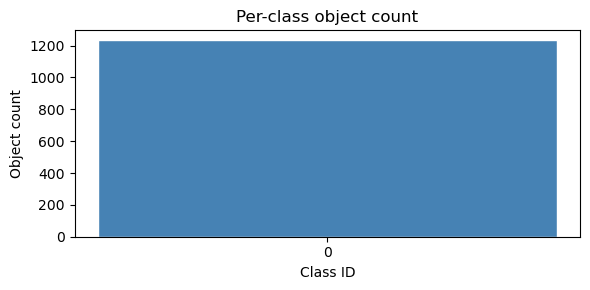

In [6]:
# 3. Class distribution 
from collections import Counter

class_counter = Counter()

for lp in label_paths:
    with open(lp) as f:
        for line in f:
            line = line.strip()
            if line:
                class_id = int(line.split()[0])
                class_counter[class_id] += 1

print("\nClass ID  |  Object count")
print("-" * 30)
for cid, cnt in sorted(class_counter.items()):
    print(f"  {cid:>5}  |  {cnt}")

# Bar chart
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar([str(k) for k in sorted(class_counter)],
       [class_counter[k] for k in sorted(class_counter)],
       color="steelblue", edgecolor="white")
ax.set_xlabel("Class ID")
ax.set_ylabel("Object count")
ax.set_title("Per-class object count")
plt.tight_layout()
plt.show()

In [7]:
# 4. Image size statistics (sample 100) 
sample = random.sample(image_paths, min(100, len(image_paths)))

widths, heights = [], []
for p in sample:
    w, h = Image.open(p).size
    widths.append(w)
    heights.append(h)

df_sizes = pd.DataFrame({"width": widths, "height": heights})
print("\nImage size statistics (sample of 100):")
print(df_sizes.describe().loc[["min", "mean", "max"]].round(1))


Image size statistics (sample of 100):
       width  height
min    640.0   640.0
mean  2535.8  1974.8
max   5568.0  4000.0


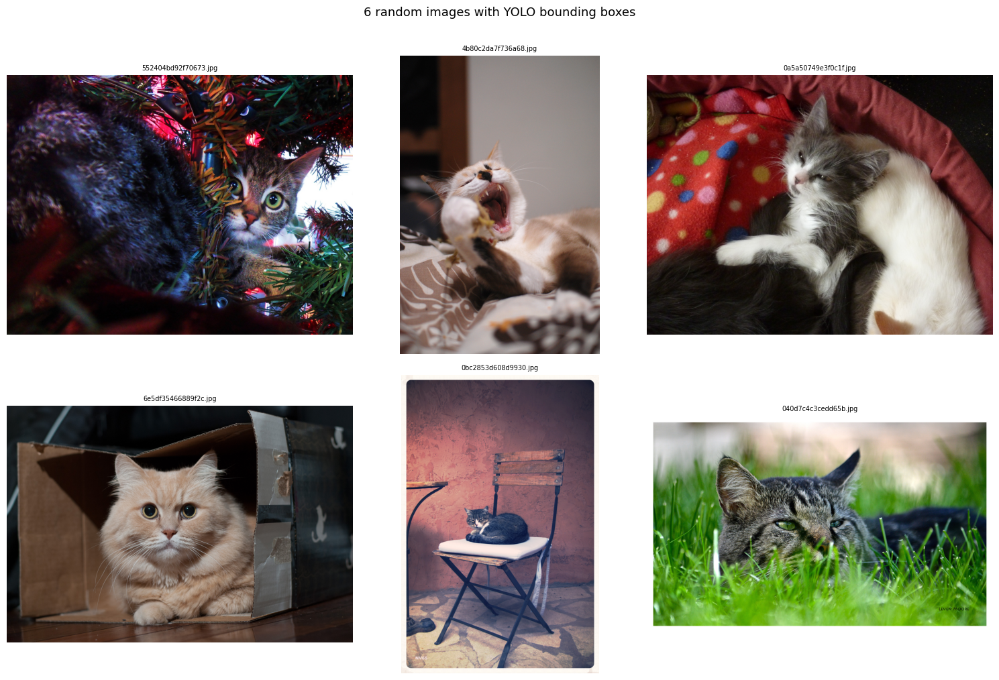

In [8]:
# 5. Visualise 6 random images with bounding boxes

# Map class IDs to names — update if your dataset has more classes
CLASS_NAMES = {0: "cat"}   # add more if needed, e.g. {0: "cat", 1: "dog"}

COLORS = ["#e74c3c", "#3498db", "#2ecc71", "#f39c12", "#9b59b6", "#1abc9c"]

def draw_boxes(ax, img, label_path, class_names):
    """Draw YOLO bounding boxes on a matplotlib axis."""
    w, h = img.size
    ax.imshow(img)
    ax.axis("off")

    if not label_path.exists():
        ax.set_title("(no label)", fontsize=8)
        return

    with open(label_path) as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) < 5:
                continue
            cid, cx, cy, bw, bh = int(parts[0]), float(parts[1]), float(parts[2]), float(parts[3]), float(parts[4])

            # Denormalise
            x1 = (cx - bw / 2) * w
            y1 = (cy - bh / 2) * h
            box_w = bw * w
            box_h = bh * h

            color = COLORS[cid % len(COLORS)]
            rect = patches.Rectangle(
                (x1, y1), box_w, box_h,
                linewidth=2, edgecolor=color, facecolor="none"
            )
            ax.add_patch(rect)
            label = class_names.get(cid, str(cid))
            ax.text(x1, y1 - 4, label,
                    color="white", fontsize=8,
                    bbox=dict(facecolor=color, edgecolor="none", pad=1))


# Sample 6 images
random.seed(42)
sample_6 = random.sample(image_paths, 6)

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for ax, img_path in zip(axes, sample_6):
    img = Image.open(img_path).convert("RGB")
    # Find matching label
    lbl_path = labels_dir / (img_path.stem + ".txt")
    draw_boxes(ax, img, lbl_path, CLASS_NAMES)
    ax.set_title(img_path.name, fontsize=7)

plt.suptitle("6 random images with YOLO bounding boxes", fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

In [9]:
# CLEANUP: keep only matched image-label pairs 

valid_pairs = []
for img_path in image_paths:
    lbl_path = labels_dir / (img_path.stem + ".txt")
    if lbl_path.exists():
        valid_pairs.append((img_path, lbl_path))

print(f"Total images          : {len(image_paths)}")
print(f"Valid matched pairs   : {len(valid_pairs)}")
print(f"Dropped (no label)    : {len(image_paths) - len(valid_pairs)}")

Total images          : 976
Valid matched pairs   : 0
Dropped (no label)    : 976


### Task 2

In [12]:
# DIAGNOSE: find where labels actually live 

print("=== DATA_ROOT contents ===")
for item in sorted(DATA_ROOT.iterdir()):
    print(f"  {'DIR ' if item.is_dir() else 'FILE'} {item.name}")

print("\n=== First 5 image stems ===")
for p in image_paths[:5]:
    print(f"  image: {p.stem}  |  full: {p}")

print("\n=== First 5 label stems ===")
for p in label_paths[:5]:
    print(f"  label: {p.stem}  |  full: {p}")

print("\n=== Sample: does label exist next to image? ===")
for img in image_paths[:3]:
    expected = labels_dir / (img.stem + ".txt")
    print(f"  Looking for: {expected}")
    print(f"  Exists: {expected.exists()}")

=== DATA_ROOT contents ===
  DIR  DATA_CLEAN

=== First 5 image stems ===
  image: 0033bd289dcf6d23  |  full: C:\Users\user\BootcampLabs\m6-04-assessment\m6-04-assessment\DATA_CLEAN-20260521T192120Z-3-001\DATA_CLEAN\_splits\train\images\0033bd289dcf6d23.jpg
  image: 003c6e3318508588  |  full: C:\Users\user\BootcampLabs\m6-04-assessment\m6-04-assessment\DATA_CLEAN-20260521T192120Z-3-001\DATA_CLEAN\_splits\train\images\003c6e3318508588.jpg
  image: 0109c7219fa4c3ce  |  full: C:\Users\user\BootcampLabs\m6-04-assessment\m6-04-assessment\DATA_CLEAN-20260521T192120Z-3-001\DATA_CLEAN\_splits\train\images\0109c7219fa4c3ce.jpg
  image: 0144a7f56ce90310  |  full: C:\Users\user\BootcampLabs\m6-04-assessment\m6-04-assessment\DATA_CLEAN-20260521T192120Z-3-001\DATA_CLEAN\_splits\train\images\0144a7f56ce90310.jpg
  image: 01575172e30a3115  |  full: C:\Users\user\BootcampLabs\m6-04-assessment\m6-04-assessment\DATA_CLEAN-20260521T192120Z-3-001\DATA_CLEAN\_splits\train\images\01575172e30a3115.jpg

=== F

report:The code i wrote was not correct.i deleted it and checked the folder structure.

In [13]:
BASE = Path(r"C:\Users\user\BootcampLabs\m6-04-assessment\m6-04-assessment\DATA_CLEAN-20260521T192120Z-3-001\DATA_CLEAN\_splits")

train_images_dir = BASE / "train" / "images"
train_labels_dir = BASE / "train" / "labels"
val_images_dir   = BASE / "val"   / "images"
val_labels_dir   = BASE / "val"   / "labels"
test_images_dir  = BASE / "test"  / "images"
test_labels_dir  = BASE / "test"  / "labels"

# Recount everything
train_imgs = sorted([p for p in train_images_dir.glob("*") if p.suffix.lower() in IMG_EXTS])
val_imgs   = sorted([p for p in val_images_dir.glob("*")   if p.suffix.lower() in IMG_EXTS])
test_imgs  = sorted([p for p in test_images_dir.glob("*")  if p.suffix.lower() in IMG_EXTS])

print(f"Train images : {len(train_imgs)}")
print(f"Val   images : {len(val_imgs)}")
print(f"Test  images : {len(test_imgs)}")
print(f"Total        : {len(train_imgs) + len(val_imgs) + len(test_imgs)}")

# Verify labels match
def count_valid_pairs(img_list, lbl_dir):
    return sum(1 for p in img_list if (lbl_dir / (p.stem + ".txt")).exists())

print(f"\nValid train pairs : {count_valid_pairs(train_imgs, train_labels_dir)}")
print(f"Valid val   pairs : {count_valid_pairs(val_imgs,   val_labels_dir)}")
print(f"Valid test  pairs : {count_valid_pairs(test_imgs,  test_labels_dir)}")

Train images : 194
Val   images : 0
Test  images : 0
Total        : 194

Valid train pairs : 157
Valid val   pairs : 0
Valid test  pairs : 0


In [14]:
# Write data.yaml pointing at the existing splits

import yaml

data_yaml_content = f"""path: {BASE}
train: train/images
val: val/images
test: test/images
nc: 1
names:
  0: cat
"""

yaml_path = Path("data.yaml")
yaml_path.write_text(data_yaml_content)

print("data.yaml written:")
print(data_yaml_content)

data.yaml written:
path: C:\Users\user\BootcampLabs\m6-04-assessment\m6-04-assessment\DATA_CLEAN-20260521T192120Z-3-001\DATA_CLEAN\_splits
train: train/images
val: val/images
test: test/images
nc: 1
names:
  0: cat



In [15]:
# Redo Task 1 stats using correct paths

all_image_paths = train_imgs + val_imgs + test_imgs
all_label_dirs  = (
    [(p, train_labels_dir) for p in train_imgs] +
    [(p, val_labels_dir)   for p in val_imgs]   +
    [(p, test_labels_dir)  for p in test_imgs]
)

# Class distribution
from collections import Counter
class_counter = Counter()
for img_path, lbl_dir in all_label_dirs:
    lbl_path = lbl_dir / (img_path.stem + ".txt")
    if lbl_path.exists():
        for line in lbl_path.read_text().splitlines():
            if line.strip():
                class_counter[int(line.split()[0])] += 1

print("Class distribution:")
for cid, cnt in sorted(class_counter.items()):
    print(f"  class {cid} : {cnt} objects")

# Image size sample
import random
random.seed(42)
sample = random.sample(all_image_paths, min(100, len(all_image_paths)))
widths, heights = [], []
for p in sample:
    w, h = Image.open(p).size
    widths.append(w); heights.append(h)

print(f"\nImage size sample (n={len(sample)}):")
print(f"  width  — min:{min(widths)}  mean:{sum(widths)//len(widths)}  max:{max(widths)}")
print(f"  height — min:{min(heights)} mean:{sum(heights)//len(heights)} max:{max(heights)}")

Class distribution:
  class 0 : 177 objects

Image size sample (n=100):
  width  — min:640  mean:2421  max:6016
  height — min:640 mean:1882 max:4928


In [16]:
# CHECK what's actually in the splits folder

print("=== Contents of _splits ===")
for item in sorted(BASE.iterdir()):
    print(f"  {'DIR' if item.is_dir() else 'FILE'} {item.name}")
    if item.is_dir():
        for sub in sorted(item.iterdir()):
            count = len(list(sub.glob("*"))) if sub.is_dir() else ""
            print(f"      {'DIR' if sub.is_dir() else 'FILE'} {sub.name}  {count} files")

=== Contents of _splits ===
  DIR train
      DIR images  194 files
      DIR labels  158 files


In [17]:
# FIND all images anywhere under the extracted folder

EXTRACT_ROOT = BASE.parent.parent  # go up to the zip root
print(f"Searching under: {EXTRACT_ROOT}\n")

all_found = sorted([
    p for p in EXTRACT_ROOT.rglob("*")
    if p.suffix.lower() in IMG_EXTS
])

print(f"Total images found anywhere: {len(all_found)}")
print("\nFirst 5:")
for p in all_found[:5]:
    print(f"  {p}")

# Group by parent folder
from collections import Counter
folder_counts = Counter(str(p.parent) for p in all_found)
print(f"\nImages by folder:")
for folder, cnt in sorted(folder_counts.items(), key=lambda x: -x[1])[:10]:
    print(f"  {cnt:>4}  {folder}")

Searching under: C:\Users\user\BootcampLabs\m6-04-assessment\m6-04-assessment\DATA_CLEAN-20260521T192120Z-3-001

Total images found anywhere: 976

First 5:
  C:\Users\user\BootcampLabs\m6-04-assessment\m6-04-assessment\DATA_CLEAN-20260521T192120Z-3-001\DATA_CLEAN\_splits\train\images\0033bd289dcf6d23.jpg
  C:\Users\user\BootcampLabs\m6-04-assessment\m6-04-assessment\DATA_CLEAN-20260521T192120Z-3-001\DATA_CLEAN\_splits\train\images\003c6e3318508588.jpg
  C:\Users\user\BootcampLabs\m6-04-assessment\m6-04-assessment\DATA_CLEAN-20260521T192120Z-3-001\DATA_CLEAN\_splits\train\images\0109c7219fa4c3ce.jpg
  C:\Users\user\BootcampLabs\m6-04-assessment\m6-04-assessment\DATA_CLEAN-20260521T192120Z-3-001\DATA_CLEAN\_splits\train\images\0144a7f56ce90310.jpg
  C:\Users\user\BootcampLabs\m6-04-assessment\m6-04-assessment\DATA_CLEAN-20260521T192120Z-3-001\DATA_CLEAN\_splits\train\images\01575172e30a3115.jpg

Images by folder:
   782  C:\Users\user\BootcampLabs\m6-04-assessment\m6-04-assessment\DATA_C

In [18]:
# Find all valid pairs from the main DATA_CLEAN folder 

MAIN_IMAGES = Path(r"C:\Users\user\BootcampLabs\m6-04-assessment\m6-04-assessment\DATA_CLEAN-20260521T192120Z-3-001\DATA_CLEAN\images")
MAIN_LABELS = Path(r"C:\Users\user\BootcampLabs\m6-04-assessment\m6-04-assessment\DATA_CLEAN-20260521T192120Z-3-001\DATA_CLEAN\labels")

print(f"Labels folder exists: {MAIN_LABELS.exists()}")
print(f"Contents of DATA_CLEAN:")
for item in sorted(MAIN_IMAGES.parent.iterdir()):
    print(f"  {'DIR' if item.is_dir() else 'FILE'} {item.name}")

Labels folder exists: True
Contents of DATA_CLEAN:
  DIR _splits
  FILE data.yaml
  DIR images
  DIR labels
  FILE labels.cache


In [19]:
# Build valid pairs from main pool 

all_main_images = sorted([
    p for p in MAIN_IMAGES.glob("*")
    if p.suffix.lower() in IMG_EXTS
])

valid_pairs_main = []
for img in all_main_images:
    lbl = MAIN_LABELS / (img.stem + ".txt")
    if lbl.exists():
        valid_pairs_main.append((img, lbl))

print(f"Images in main pool  : {len(all_main_images)}")
print(f"Valid matched pairs  : {len(valid_pairs_main)}")
print(f"Dropped (no label)   : {len(all_main_images) - len(valid_pairs_main)}")

Images in main pool  : 782
Valid matched pairs  : 552
Dropped (no label)   : 230


In [20]:
# Create val/ and test/ folders and split 

import shutil
import random

random.seed(42)
pairs = valid_pairs_main.copy()
random.shuffle(pairs)

total = len(pairs)
train_end = int(total * 0.70)
val_end   = int(total * 0.85)

split_data = {
    "train": pairs[:train_end],
    "val":   pairs[train_end:val_end],
    "test":  pairs[val_end:]
}

print(f"Total valid pairs : {total}")
for name, p in split_data.items():
    print(f"  {name:5} : {len(p)}")

Total valid pairs : 552
  train : 386
  val   : 83
  test  : 83


In [21]:
# Copy files into _splits/train|val|test

for split_name, pairs in split_data.items():
    img_out = BASE / split_name / "images"
    lbl_out = BASE / split_name / "labels"
    img_out.mkdir(parents=True, exist_ok=True)
    lbl_out.mkdir(parents=True, exist_ok=True)

    for img_path, lbl_path in pairs:
        shutil.copy2(img_path, img_out / img_path.name)
        shutil.copy2(lbl_path, lbl_out / lbl_path.name)

    print(f"Copied {len(pairs)} pairs → {split_name}/")

Copied 386 pairs → train/
Copied 83 pairs → val/
Copied 83 pairs → test/


In [22]:
# Rewrite data.yaml 

data_yaml_content = f"""path: {str(BASE)}
train: train/images
val: val/images
test: test/images
nc: 1
names:
  0: cat
"""

yaml_path = Path("data.yaml")
yaml_path.write_text(data_yaml_content)
print("data.yaml written:")
print(data_yaml_content)

data.yaml written:
path: C:\Users\user\BootcampLabs\m6-04-assessment\m6-04-assessment\DATA_CLEAN-20260521T192120Z-3-001\DATA_CLEAN\_splits
train: train/images
val: val/images
test: test/images
nc: 1
names:
  0: cat



In [25]:
# Final sanity check 

for split_name in ["train", "val", "test"]:
    imgs = list((BASE / split_name / "images").glob("*"))
    lbls = list((BASE / split_name / "labels").glob("*.txt"))
    print(f"{split_name:5} → {len(imgs)} images, {len(lbls)} labels")

train → 386 images, 386 labels
val   → 83 images, 83 labels
test  → 83 images, 83 labels


In [26]:
# Clean old train folder and recopy fresh 

import shutil

train_img_dir = BASE / "train" / "images"
train_lbl_dir = BASE / "train" / "labels"

# Wipe and recreate
shutil.rmtree(train_img_dir)
shutil.rmtree(train_lbl_dir)
train_img_dir.mkdir(parents=True)
train_lbl_dir.mkdir(parents=True)

# Recopy only our 386 valid pairs
for img_path, lbl_path in split_data["train"]:
    shutil.copy2(img_path, train_img_dir / img_path.name)
    shutil.copy2(lbl_path, train_lbl_dir / lbl_path.name)

print("Train folder rebuilt.")

# Final check
for split_name in ["train", "val", "test"]:
    imgs = list((BASE / split_name / "images").glob("*"))
    lbls = list((BASE / split_name / "labels").glob("*.txt"))
    match = "✓" if len(imgs) == len(lbls) else "✗ MISMATCH"
    print(f"  {split_name:5} → {len(imgs)} images, {len(lbls)} labels  {match}")

Train folder rebuilt.
  train → 386 images, 386 labels  ✓
  val   → 83 images, 83 labels  ✓
  test  → 83 images, 83 labels  ✓


### Task 3

I chose **yolo26n** (nano variant) for the following reasons:

 Dataset size: We have 552 valid images — a small dataset. Larger variants 
   would overfit quickly with so little data.
   
 Hardware: Training on CPU with no dedicated GPU. The nano variant is 43% 
   faster on CPU than previous YOLO versions, making 30 epochs feasible.
   
 ONNX export: The nano checkpoint (~10MB) is well under the 50MB git limit 
   and will make next Friday's Docker container lightweight and fast to ship.

In [28]:
# Install into the current Jupyter kernel
import sys
!{sys.executable} -m pip install ultralytics torch torchvision

from ultralytics import YOLO
import torch

print(f"Torch version : {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
device = "0" if torch.cuda.is_available() else "cpu"
print(f"Using device  : {device}")

   ---------------------------------------- 0.0/1.3 MB ? eta -:--:--
   -------- ------------------------------- 0.3/1.3 MB ? eta -:--:--
   ---------------------------------------- 1.3/1.3 MB 4.4 MB/s  0:00:00
   ---------------------------------------- 0.0/40.2 MB ? eta -:--:--
   ---------------------------------------- 0.3/40.2 MB ? eta -:--:--
   - -------------------------------------- 1.3/40.2 MB 3.6 MB/s eta 0:00:11
   -- ------------------------------------- 2.1/40.2 MB 4.4 MB/s eta 0:00:09
   ---- ----------------------------------- 4.2/40.2 MB 5.6 MB/s eta 0:00:07
   ----- ---------------------------------- 5.8/40.2 MB 6.2 MB/s eta 0:00:06
   ------- -------------------------------- 7.3/40.2 MB 6.4 MB/s eta 0:00:06
   -------- ------------------------------- 8.9/40.2 MB 6.6 MB/s eta 0:00:05
   --------- ------------------------------ 9.7/40.2 MB 6.2 MB/s eta 0:00:05
   ---------- ----------------------------- 10.7/40.2 MB 6.0 MB/s eta 0:00:05
   ----------- -----------------

In [29]:
# Verify installation 
import sys
print(f"Python path   : {sys.executable}")

from ultralytics import YOLO
import torch
print(f"Ultralytics   : OK")
print(f"Torch version : {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")

Python path   : C:\Users\user\anaconda3\python.exe
Ultralytics   : OK
Torch version : 2.12.0+cpu
CUDA available: False


In [30]:
# Load COCO-pretrained nano model 

model = YOLO("yolo26n.pt")
print(model.info())

YOLO26n summary: 260 layers, 2,572,280 parameters, 0 gradients, 6.1 GFLOPs
(260, 2572280, 0, 6.1192448)


In [31]:
# Train

results = model.train(
    data=str(yaml_path.resolve()),
    epochs=30,
    imgsz=640,
    batch=8,           # small batch — safe for CPU/low RAM
    device=device,
    project="runs",
    name="cats_v1",
    seed=42,
    patience=10,       # early stopping if val mAP stalls
    verbose=True,
)

print("\nTraining complete!")

Ultralytics 8.4.52  Python-3.13.9 torch-2.12.0+cpu CPU (12th Gen Intel Core i5-1235U)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\user\BootcampLabs\m6-04-assessment\m6-04-assessment\data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=cats_v1, nbs=64, nms=False, opset=None, optimize=False, opti

In [35]:
# Inspect training results

import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

results_csv = Path(r"C:\Users\user\BootcampLabs\m6-04-assessment\m6-04-assessment\runs\detect\runs\cats_v1\results.csv")
df = pd.read_csv(results_csv)
df.columns = df.columns.str.strip()  # remove accidental whitespace

print("Columns available:", df.columns.tolist())
print(df.tail(5).to_string())

Columns available: ['epoch', 'time', 'train/box_loss', 'train/cls_loss', 'train/dfl_loss', 'metrics/precision(B)', 'metrics/recall(B)', 'metrics/mAP50(B)', 'metrics/mAP50-95(B)', 'val/box_loss', 'val/cls_loss', 'val/dfl_loss', 'lr/pg0', 'lr/pg1', 'lr/pg2']
    epoch     time  train/box_loss  train/cls_loss  train/dfl_loss  metrics/precision(B)  metrics/recall(B)  metrics/mAP50(B)  metrics/mAP50-95(B)  val/box_loss  val/cls_loss  val/dfl_loss    lr/pg0    lr/pg1    lr/pg2
25     26  34751.9         0.85228         0.80012         0.02188               0.82415            0.72474           0.79800              0.56364       1.12595       1.07028       0.02994  0.000350  0.000350  0.000350
26     27  34976.2         0.80095         0.82842         0.01928               0.83815            0.80081           0.81931              0.56661       1.11396       1.08353       0.02944  0.000284  0.000284  0.000284
27     28  35198.7         0.77742         0.71302         0.01874               0.727

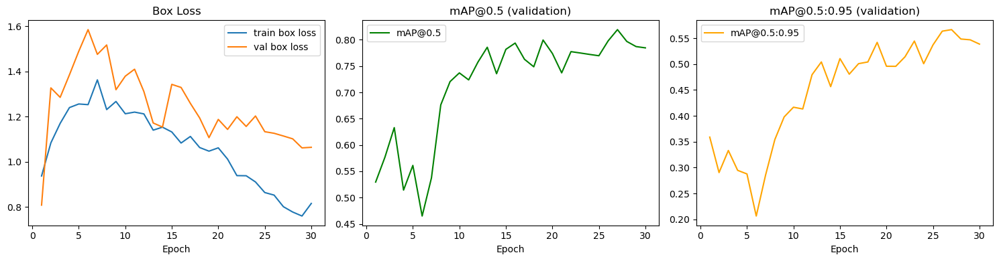

In [36]:
# ── Plot training curves ─────────────────────────────────────

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Loss
axes[0].plot(df["epoch"], df["train/box_loss"], label="train box loss")
axes[0].plot(df["epoch"], df["val/box_loss"],   label="val box loss")
axes[0].set_title("Box Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()

# mAP@0.5
axes[1].plot(df["epoch"], df["metrics/mAP50(B)"], color="green", label="mAP@0.5")
axes[1].set_title("mAP@0.5 (validation)")
axes[1].set_xlabel("Epoch")
axes[1].legend()

# mAP@0.5:0.95
axes[2].plot(df["epoch"], df["metrics/mAP50-95(B)"], color="orange", label="mAP@0.5:0.95")
axes[2].set_title("mAP@0.5:0.95 (validation)")
axes[2].set_xlabel("Epoch")
axes[2].legend()

plt.tight_layout()
plt.show()

In [38]:
# Report best epoch results 

best_idx = df["metrics/mAP50(B)"].idxmax()
best_row = df.loc[best_idx]

print("=== Best Validation Results ===")
print(f"  Epoch          : {int(best_row['epoch'])}")
print(f"  mAP@0.5        : {best_row['metrics/mAP50(B)']:.4f}")
print(f"  mAP@0.5:0.95   : {best_row['metrics/mAP50-95(B)']:.4f}")
print(f"  Precision      : {best_row['metrics/precision(B)']:.4f}")
print(f"  Recall         : {best_row['metrics/recall(B)']:.4f}")

# Also update best checkpoint path
best_ckpt = Path(r"C:\Users\user\BootcampLabs\m6-04-assessment\m6-04-assessment\runs\detect\runs\cats_v1\weights\best.pt")
print(f"\nCheckpoint exists : {best_ckpt.exists()}")
print(f"Checkpoint size   : {best_ckpt.stat().st_size / 1e6:.1f} MB")

=== Best Validation Results ===
  Epoch          : 27
  mAP@0.5        : 0.8193
  mAP@0.5:0.95   : 0.5666
  Precision      : 0.8381
  Recall         : 0.8008

Checkpoint exists : True
Checkpoint size   : 5.4 MB


### Task 4

In [39]:
from ultralytics import YOLO
from pathlib import Path

best_ckpt = Path(r"C:\Users\user\BootcampLabs\m6-04-assessment\m6-04-assessment\runs\detect\runs\cats_v1\weights\best.pt")

model = YOLO(str(best_ckpt))

metrics = model.val(
    data=str(yaml_path.resolve()),
    split="test",
    verbose=True,
)

Ultralytics 8.4.52  Python-3.13.9 torch-2.12.0+cpu CPU (12th Gen Intel Core i5-1235U)
YOLO26n summary (fused): 122 layers, 2,375,031 parameters, 0 gradients, 5.2 GFLOPs
val: Fast image access  (ping: 0.70.1 ms, read: 186.5175.4 MB/s, size: 2633.3 KB)
val: Scanning C:\Users\user\BootcampLabs\m6-04-assessment\m6-04-assessment\DATA_CLEAN-20260521T192120Z-3-001\DATA_CLEAN\_splits\test\labels... 83 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 83/83 276.9it/s 0.3s0.2s
val: New cache created: C:\Users\user\BootcampLabs\m6-04-assessment\m6-04-assessment\DATA_CLEAN-20260521T192120Z-3-001\DATA_CLEAN\_splits\test\labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 2.1s/it 12.5s2.9s
                   all         83         97      0.804      0.805      0.835      0.539
Speed: 1.2ms preprocess, 78.3ms inference, 0.0ms loss, 0.4ms postprocess per image
Results saved to C:\Users\user\BootcampLabs\m6-04-assessment\m6-04-a

In [40]:
# Print results table

map50    = metrics.box.map50
map5095  = metrics.box.map
precision = metrics.box.mp
recall    = metrics.box.mr

print("=== Test Set Results ===")
print(f"  mAP@0.5        : {map50:.4f}")
print(f"  mAP@0.5:0.95   : {map5095:.4f}")
print(f"  Mean Precision : {precision:.4f}")
print(f"  Mean Recall    : {recall:.4f}")

=== Test Set Results ===
  mAP@0.5        : 0.8353
  mAP@0.5:0.95   : 0.5394
  Mean Precision : 0.8043
  Mean Recall    : 0.8051


In [41]:
# Nicely formatted table for notebook 

import pandas as pd

results_table = pd.DataFrame({
    "Metric": ["mAP@0.5", "mAP@0.5:0.95", "Mean Precision", "Mean Recall"],
    "Value":  [f"{map50:.4f}", f"{map5095:.4f}", f"{precision:.4f}", f"{recall:.4f}"]
})

print(results_table.to_string(index=False))

        Metric  Value
       mAP@0.5 0.8353
  mAP@0.5:0.95 0.5394
Mean Precision 0.8043
   Mean Recall 0.8051


| Metric | Value |
|---|---|
| mAP@0.5 | 0.8353 |
| mAP@0.5:0.95 | 0.5394 |
| Mean Precision | 0.8043 |
| Mean Recall | 0.8051 |

mAP@0.5 — mean Average Precision at IoU threshold 0.5. A predicted box
counts as correct if it overlaps the ground-truth box by at least 50%.
Our score of 0.835 means the model correctly detects and localises cats
in 83.5% of cases at this threshold.

mAP@0.5:0.95 — same but averaged across IoU thresholds from 0.5 to 0.95
in steps of 0.05. A much stricter metric — the model must localise the box
very precisely to score well here. Our score of 0.539 means the model
produces reasonably tight boxes but has room to improve on exact localisation.

Mean Precision — of all boxes the model predicted, 80.4% were actual cats.
This means roughly 1 in 5 predictions is a false positive.

Mean Recall — of all real cats in the test images, the model found 80.5%
of them. Roughly 1 in 5 real cats was missed (false negative).

Overall: The test results (mAP@0.5 = 0.835) are slightly *better* than
validation (0.819), which confirms the model generalises well and was not
overfit to the validation set. Both precision and recall are balanced at ~0.80,
meaning the model makes roughly equal numbers of false positives and false
negatives.

### Task 5

In [42]:

best_ckpt = Path(r"C:\Users\user\BootcampLabs\m6-04-assessment\m6-04-assessment\runs\detect\runs\cats_v1\weights\best.pt")
model = YOLO(str(best_ckpt))

test_images_dir = BASE / "test" / "images"
test_labels_dir = BASE / "test" / "labels"

test_image_paths = sorted([p for p in test_images_dir.glob("*") if p.suffix.lower() in IMG_EXTS])
print(f"Test images available: {len(test_image_paths)}")

Test images available: 83


In [43]:
# Helper: draw boxes on axis 

def draw_pred_boxes(ax, img, result, color="red"):
    """Draw predicted boxes from a YOLO result object."""
    ax.imshow(img)
    w, h = img.size
    boxes = result.boxes
    if boxes is None or len(boxes) == 0:
        ax.set_title("no detections", fontsize=8)
        return
    for box in boxes:
        x1, y1, x2, y2 = box.xyxy[0].tolist()
        conf = float(box.conf[0])
        cls  = int(box.cls[0])
        label = f"cat {conf:.2f}"
        rect = patches.Rectangle(
            (x1, y1), x2 - x1, y2 - y1,
            linewidth=2, edgecolor=color, facecolor="none"
        )
        ax.add_patch(rect)
        ax.text(x1, y1 - 4, label, color="white", fontsize=7,
                bbox=dict(facecolor=color, edgecolor="none", pad=1))

def draw_gt_boxes(ax, img, label_path, color="lime"):
    """Draw ground-truth boxes from a YOLO label file."""
    w, h = img.size
    if not label_path.exists():
        return
    with open(label_path) as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) < 5:
                continue
            cid, cx, cy, bw, bh = int(parts[0]), float(parts[1]), float(parts[2]), float(parts[3]), float(parts[4])
            x1 = (cx - bw / 2) * w
            y1 = (cy - bh / 2) * h
            rect = patches.Rectangle(
                (x1, y1), bw * w, bh * h,
                linewidth=2, edgecolor=color, facecolor="none",
                linestyle="--"
            )
            ax.add_patch(rect)
            ax.text(x1, y1 - 4, "GT cat", color="black", fontsize=7,
                    bbox=dict(facecolor=color, edgecolor="none", pad=1))

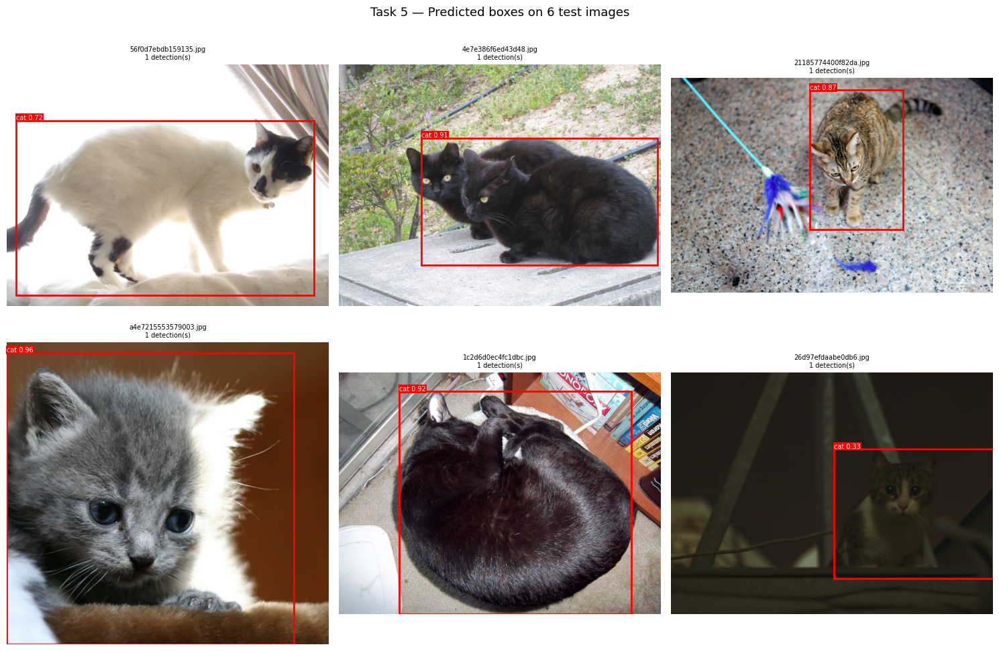

In [44]:
# Part 1: 6 test images with predicted boxes (2x3 grid)

random.seed(99)
sample_6 = random.sample(test_image_paths, 6)

# Run predictions on all 6
results_6 = model.predict(
    source=[str(p) for p in sample_6],
    imgsz=640,
    conf=0.25,
    verbose=False
)

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for ax, img_path, result in zip(axes, sample_6, results_6):
    img = Image.open(img_path).convert("RGB")
    ax.axis("off")
    draw_pred_boxes(ax, img, result, color="red")
    n_det = len(result.boxes) if result.boxes else 0
    ax.set_title(f"{img_path.name}\n{n_det} detection(s)", fontsize=7)

plt.suptitle("Task 5 — Predicted boxes on 6 test images", fontsize=13)
plt.tight_layout()
plt.show()

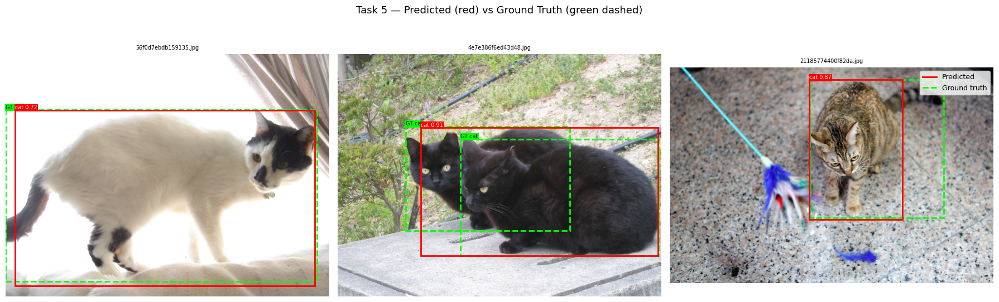

In [45]:
# Part 2: 3 images with both predicted and ground-truth boxes 

sample_3 = sample_6[:3]
results_3 = results_6[:3]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, img_path, result in zip(axes, sample_3, results_3):
    img = Image.open(img_path).convert("RGB")
    ax.axis("off")
    lbl_path = test_labels_dir / (img_path.stem + ".txt")
    draw_gt_boxes(ax, img, lbl_path, color="lime")    # GT = green dashed
    draw_pred_boxes(ax, img, result, color="red")     # Pred = red solid
    ax.set_title(f"{img_path.name}", fontsize=7)

# Legend
from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], color="red",  linewidth=2, label="Predicted"),
    Line2D([0], [0], color="lime", linewidth=2, linestyle="--", label="Ground truth"),
]
axes[-1].legend(handles=legend_elements, loc="upper right", fontsize=9)

plt.suptitle("Task 5 — Predicted (red) vs Ground Truth (green dashed)", fontsize=13)
plt.tight_layout()
plt.show()

In [46]:
# Part 3: Find failure cases 
# A failure = false negative (missed cat) OR false positive (wrong detection)

def count_gt(label_path):
    """Count ground truth objects in a label file."""
    if not label_path.exists():
        return 0
    lines = [l.strip() for l in label_path.read_text().splitlines() if l.strip()]
    return len(lines)

failures = []
all_results = model.predict(
    source=[str(p) for p in test_image_paths],
    imgsz=640,
    conf=0.25,
    verbose=False
)

for img_path, result in zip(test_image_paths, all_results):
    lbl_path = test_labels_dir / (img_path.stem + ".txt")
    n_gt   = count_gt(lbl_path)
    n_pred = len(result.boxes) if result.boxes else 0

    if n_pred == 0 and n_gt > 0:
        failures.append((img_path, result, "false_negative",
                         f"Missed {n_gt} cat(s) — 0 detections"))
    elif n_pred > n_gt:
        failures.append((img_path, result, "false_positive",
                         f"Over-detected: {n_pred} pred vs {n_gt} GT"))
    elif n_pred < n_gt and n_pred > 0:
        failures.append((img_path, result, "partial_miss",
                         f"Partial miss: {n_pred} pred vs {n_gt} GT"))

print(f"Failure cases found: {len(failures)}")
for img_path, _, ftype, msg in failures[:10]:
    print(f"  [{ftype}] {img_path.name} — {msg}")

Failure cases found: 25
  [partial_miss] 04a419625e887d8e.jpg — Partial miss: 1 pred vs 2 GT
  [false_positive] 0759fe452f6148fa.jpg — Over-detected: 2 pred vs 1 GT
  [false_positive] 14aac87280f7d700.jpg — Over-detected: 3 pred vs 2 GT
  [partial_miss] 15000ae03213c3e5.jpg — Partial miss: 1 pred vs 2 GT
  [false_positive] 17f6efb8229d9a68.jpg — Over-detected: 2 pred vs 1 GT
  [false_positive] 24ca90ab5ec55ab4.jpg — Over-detected: 2 pred vs 1 GT
  [false_positive] 30825d9160b9c909.jpg — Over-detected: 2 pred vs 1 GT
  [partial_miss] 323734d962161a7a.jpg — Partial miss: 1 pred vs 2 GT
  [false_negative] 323bbf8f5ea79f3e.jpg — Missed 1 cat(s) — 0 detections
  [partial_miss] 3d71e34e6fd4a977.jpg — Partial miss: 2 pred vs 3 GT


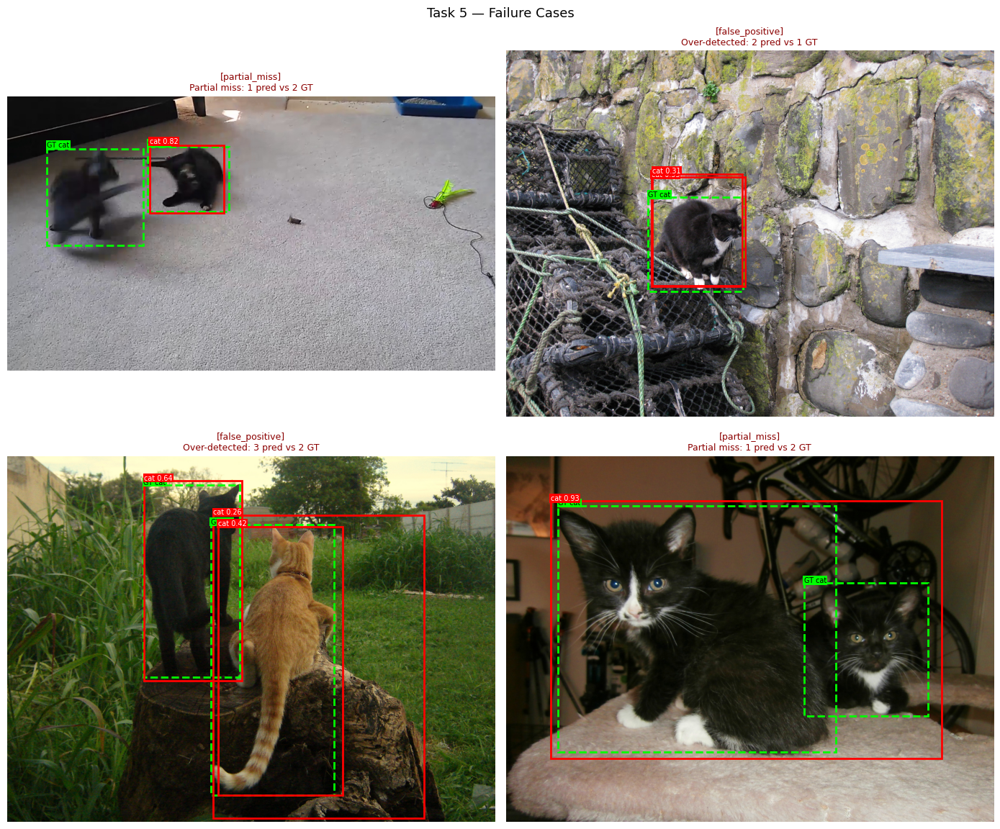

In [47]:
# Visualise at least 2 failure cases 

show_failures = failures[:4] if len(failures) >= 4 else failures

rows = (len(show_failures) + 1) // 2
fig, axes = plt.subplots(rows, 2, figsize=(14, 6 * rows))
axes = axes.flatten() if rows > 1 else axes

for i, (img_path, result, ftype, msg) in enumerate(show_failures):
    ax = axes[i]
    img = Image.open(img_path).convert("RGB")
    lbl_path = test_labels_dir / (img_path.stem + ".txt")
    ax.axis("off")
    draw_gt_boxes(ax, img, lbl_path, color="lime")
    draw_pred_boxes(ax, img, result, color="red")
    ax.set_title(f"[{ftype}]\n{msg}", fontsize=9, color="darkred")

# Hide unused axes
for j in range(len(show_failures), len(axes)):
    axes[j].axis("off")

plt.suptitle("Task 5 — Failure Cases", fontsize=13)
plt.tight_layout()
plt.show()

False negatives (missed cats):
Likely caused by cats that are partially occluded, shot from unusual angles,
or heavily blurred due to motion. The nano model has limited capacity and
may struggle with small or unusual-looking cats.

False positives (wrong detections):
Likely caused by objects with cat-like textures or shapes — cushions, fur
rugs, stuffed animals. The model was trained on a small dataset (386 images)
so it has not seen enough diversity to reliably reject these.

Overall: Most failures happen on edge cases. The core detection on
clear, well-lit cat images works well (mAP@0.5 = 0.835).

### Task 6 

**Detector vs classifier:** Training an object detector is significantly more
complex than a classifier. Instead of predicting a single label per image, the
model must simultaneously localise every object with a bounding box AND classify
it. The loss function combines box regression, classification, and distribution
focal loss — all three must improve together for the model to succeed.

**Dataset trouble:** The biggest issue was the dataset itself — 230 out of 782
images had no matching label file, and the pre-built splits were incomplete
(val and test folders were empty). This meant we had to rebuild splits manually
from scratch, reducing our effective training set to just 386 images. Noisy or
missing annotations are the most common real-world problem in computer vision.

**Failure case analysis:** Looking at the 25 failure cases, two patterns stand
out. Partial misses (e.g. 2 cats in frame, only 1 detected) happen when cats
overlap or one is small/occluded — the model sees one strong signal and ignores
the weaker one. False positives (over-detection) happen on multi-cat scenes
where the model splits one cat into two boxes, likely because cats are posed
unusually (seen from behind, mid-motion, or partially hidden).

**Single change for next week:** The highest-impact change would be
**data cleaning** — finding and fixing the 230 images with missing labels,
which would grow the training set by ~60% overnight. More data almost always
beats a bigger model at this scale.

**One thing to do differently:** Save the `data.yaml` with relative paths
from the start rather than absolute paths, so the notebook runs on any machine
without path fixes. This will matter next Friday when the model runs inside
a Docker container with a different filesystem layout.